# # Regresija - Predviđanje troškova zdravstvenog osiguranja
#
# Dataset `insurance.csv` sadrži podatke o osiguranicima u SAD-u: dob, spol, BMI, broj djece,
# status pušača, regiju i troškove osiguranja. Cilj je predvidjeti **charges**, odnosno
# godišnje troškove zdravstvenog osiguranja pojedine osobe.
#
# Budući da je `charges` numerička kontinuirana vrijednost, radi se o **regresijskom**
# problemu. Koriste se tri klasična modela (Random Forest, XGBoost, k-NN) i dvije neuronske
# mreže različitih arhitektura, uz eksperimente sa skaliranjem, `batch_size`, aktivacijskim
# funkcijama, Dropoutom, optimizatorom i brojem slojeva.

In [1]:
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, StandardScaler
from tensorflow import keras
from xgboost import XGBRegressor

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)

sns.set_theme(style="whitegrid")

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = PROJECT_ROOT / "data" / "insurance.csv"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "regression"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

NUMERIC_FEATURES = ["age", "bmi", "children"]
CATEGORICAL_FEATURES = ["sex", "smoker", "region"]
TARGET = "charges"
TEST_SIZE = 0.2
VALIDATION_SPLIT = 0.2

In [2]:
def save_and_show(figure, filename):
    """Sprema graf u outputs/regression i prikazuje ga inline."""
    figure.tight_layout()
    figure.savefig(OUTPUT_DIR / filename, dpi=120, bbox_inches="tight")
    plt.show()


def build_preprocessor(scaler=None):
    """ColumnTransformer: one-hot za kategorijske, opcionalni scaler za numeričke varijable."""
    numeric_transformer = "passthrough" if scaler is None else scaler
    return ColumnTransformer(
        [
            ("num", numeric_transformer, NUMERIC_FEATURES),
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL_FEATURES),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    ).set_output(transform="pandas")


def regression_metrics(actual, predicted):
    return {
        "MSE": mean_squared_error(actual, predicted),
        "MAE": mean_absolute_error(actual, predicted),
    }


def plot_actual_vs_predicted(actual, predicted, title, filename, samples=100):
    """Linijski graf stvarnih i predviđenih vrijednosti za prvih `samples` test uzoraka."""
    actual_values = np.asarray(actual)[:samples]
    predicted_values = np.asarray(predicted)[:samples]
    fig, ax = plt.subplots(figsize=(11, 4))
    ax.plot(actual_values, label="Actual", marker="o", markersize=3, linewidth=1)
    ax.plot(predicted_values, label="Predicted", marker="x", markersize=4, linewidth=1)
    ax.set_title(title)
    ax.set_xlabel(f"Test uzorak (prvih {samples})")
    ax.set_ylabel("Troškovi (USD)")
    ax.legend()
    save_and_show(fig, filename)


def build_regression_nn(input_dim, hidden_layers, activations, dropout_rate=0.0, optimizer="adam", loss="mse"):
    """Gradi regresijsku mrežu; dropout_rate se može zadati brojem ili listom po sloju."""
    dropout_rates = (
        list(dropout_rate)
        if isinstance(dropout_rate, (list, tuple))
        else [dropout_rate] * (len(hidden_layers) - 1) + [0.0]
    )
    inputs = keras.Input(shape=(input_dim,), name="features")
    x = inputs
    for neurons, activation, rate in zip(hidden_layers, activations, dropout_rates):
        x = keras.layers.Dense(neurons, activation=activation)(x)
        if rate > 0:
            x = keras.layers.Dropout(rate)(x)
    outputs = keras.layers.Dense(1, name="charges")(x)
    model = keras.Model(inputs, outputs, name="regression_nn")
    model.compile(optimizer=optimizer, loss=loss, metrics=["mae"])
    return model


def train_regression_nn(label, X_train_input, X_test_input, hidden_layers, activations,
                        dropout_rate=0.0, optimizer="adam", loss="mse", batch_size=32,
                        max_epochs=150, patience=12):
    """Trenira mrežu na skaliranom targetu i vraća predikcije u originalnim jedinicama."""
    keras.utils.set_random_seed(SEED)
    model = build_regression_nn(
        X_train_input.shape[1], hidden_layers, activations, dropout_rate, optimizer, loss
    )
    early_stopping = keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=patience, restore_best_weights=True
    )
    history = model.fit(
        X_train_input,
        y_train_scaled,
        validation_split=VALIDATION_SPLIT,
        epochs=max_epochs,
        batch_size=batch_size,
        callbacks=[early_stopping],
        verbose=0,
    )
    predicted = target_scaler.inverse_transform(
        model.predict(X_test_input, verbose=0)
    ).ravel()
    metrics = regression_metrics(y_test, predicted)
    metrics.update(
        {
            "Model": label,
            "Type": "Neural",
            "Slojevi": len(hidden_layers),
            "Neuroni": "-".join(str(n) for n in hidden_layers),
            "Aktivacije": "+".join(activations),
            "Dropout": dropout_rate,
            "Optimizer": optimizer,
            "batch_size": batch_size,
            "Epohe": len(history.history["loss"]),
        }
    )
    return model, history, predicted, metrics

# ## 1. Osnovna analiza dataseta
#
# Prije modeliranja provjeravam strukturu podataka: broj redaka i stupaca, tipove, missing
# vrijednosti, duplikate i vrijednosti kategorijskih varijabli.

In [3]:
df = pd.read_csv(DATA_PATH)
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [4]:
print(f"Broj redaka: {df.shape[0]}")
print(f"Broj stupaca: {df.shape[1]}")
df.info()

Broj redaka: 1338
Broj stupaca: 7
<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,1338.0,39.207025,14.049960,18.0000,27.00000,39.000,51.000000,64.00000
bmi,1338.0,30.663397,6.098187,15.9600,26.29625,30.400,34.693750,53.13000
children,1338.0,1.094918,1.205493,0.0000,0.00000,1.000,2.000000,5.00000
charges,1338.0,13270.422265,12110.011237,1121.8739,4740.28715,9382.033,16639.912515,63770.42801


In [6]:
missing = pd.DataFrame(
    {
        "missing": df.isna().sum(),
        "postotak": (df.isna().mean() * 100).round(2),
    }
)
missing

,missing,postotak
age,0,0.0
sex,0,0.0
bmi,0,0.0
children,0,0.0
smoker,0,0.0
region,0,0.0
charges,0,0.0


In [7]:
duplicates = df[df.duplicated(keep=False)]
print(f"Broj dupliciranih redaka: {df.duplicated().sum()}")
duplicates

Broj dupliciranih redaka: 1


,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,1639.5631
581,19,male,30.59,0,no,northwest,1639.5631


# Missing vrijednosti nema ni u jednom stupcu, pa imputacija nije potrebna.
#
# Postoji jedan redak koji se pojavljuje dvaput (sve vrijednosti su identične, uključujući
# `charges`). Takav redak ne mijenja odnos između značajki i targeta i postoji i u originalnom
# Kaggle datasetu, pa ga **zadržavam**. Zadržavanje je dosljedno u oba notebooka.

In [8]:
for column in CATEGORICAL_FEATURES:
    print(f"{column}: {sorted(df[column].unique())}")

df[["age", "bmi", "children"]].agg(["min", "max", "mean"]).round(2)

sex: ['female', 'male']
smoker: ['no', 'yes']
region: ['northeast', 'northwest', 'southeast', 'southwest']


,age,bmi,children
min,18.00,15.96,0.00
max,64.00,53.13,5.00
mean,39.21,30.66,1.09


# ## 2. Eksploratorna analiza (EDA)
#
# Cilj EDA-e je vidjeti distribucije varijabli i odnos pojedinih značajki prema troškovima.

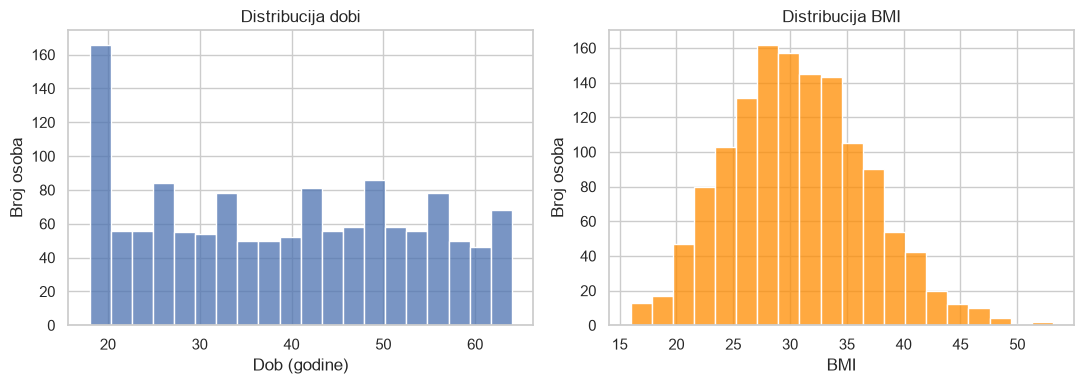

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(data=df, x="age", bins=20, ax=axes[0])
axes[0].set_title("Distribucija dobi")
axes[0].set_xlabel("Dob (godine)")
axes[0].set_ylabel("Broj osoba")
sns.histplot(data=df, x="bmi", bins=20, ax=axes[1], color="darkorange")
axes[1].set_title("Distribucija BMI")
axes[1].set_xlabel("BMI")
axes[1].set_ylabel("Broj osoba")
save_and_show(fig, "eda_hist_age_bmi.png")

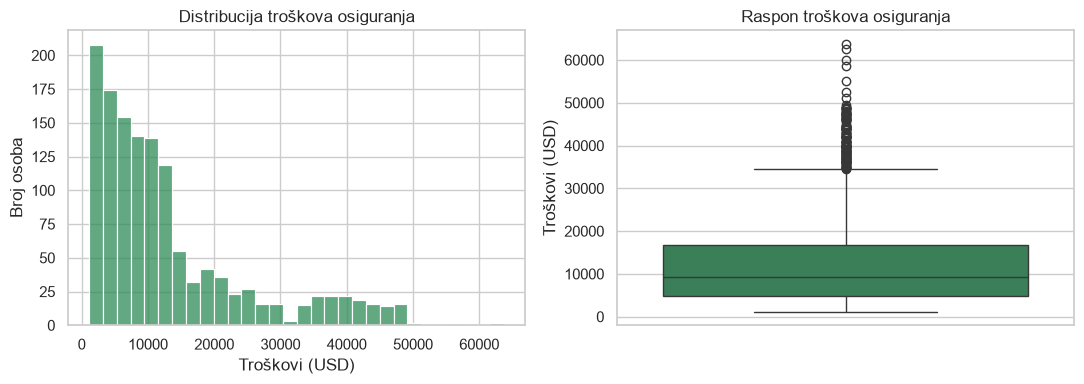

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(data=df, x="charges", bins=30, ax=axes[0], color="seagreen")
axes[0].set_title("Distribucija troškova osiguranja")
axes[0].set_xlabel("Troškovi (USD)")
axes[0].set_ylabel("Broj osoba")
sns.boxplot(data=df, y="charges", ax=axes[1], color="seagreen")
axes[1].set_title("Raspon troškova osiguranja")
axes[1].set_ylabel("Troškovi (USD)")
save_and_show(fig, "eda_charges_distribution.png")

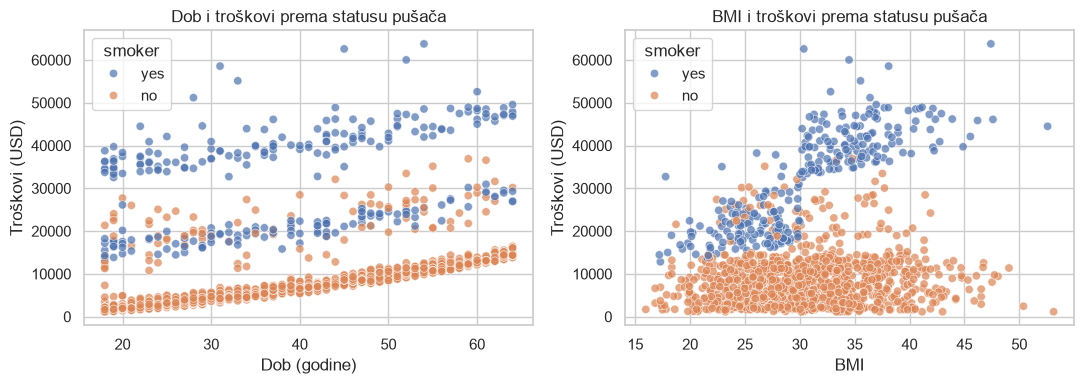

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.scatterplot(data=df, x="age", y="charges", hue="smoker", alpha=0.7, ax=axes[0])
axes[0].set_title("Dob i troškovi prema statusu pušača")
axes[0].set_xlabel("Dob (godine)")
axes[0].set_ylabel("Troškovi (USD)")
sns.scatterplot(data=df, x="bmi", y="charges", hue="smoker", alpha=0.7, ax=axes[1])
axes[1].set_title("BMI i troškovi prema statusu pušača")
axes[1].set_xlabel("BMI")
axes[1].set_ylabel("Troškovi (USD)")
save_and_show(fig, "eda_scatter_age_bmi_charges.png")

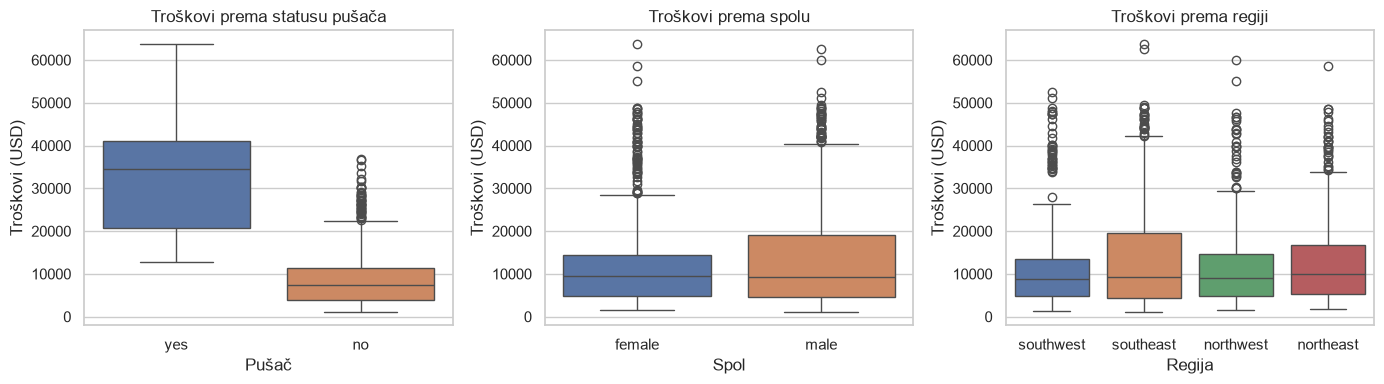

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
sns.boxplot(data=df, x="smoker", y="charges", ax=axes[0], hue="smoker", legend=False)
axes[0].set_title("Troškovi prema statusu pušača")
axes[0].set_xlabel("Pušač")
axes[0].set_ylabel("Troškovi (USD)")
sns.boxplot(data=df, x="sex", y="charges", ax=axes[1], hue="sex", legend=False)
axes[1].set_title("Troškovi prema spolu")
axes[1].set_xlabel("Spol")
axes[1].set_ylabel("Troškovi (USD)")
sns.boxplot(data=df, x="region", y="charges", ax=axes[2], hue="region", legend=False)
axes[2].set_title("Troškovi prema regiji")
axes[2].set_xlabel("Regija")
axes[2].set_ylabel("Troškovi (USD)")
save_and_show(fig, "eda_charges_boxplots.png")

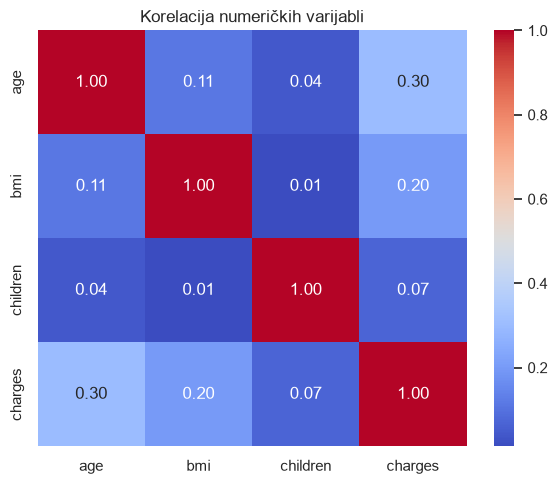

In [13]:
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(df[NUMERIC_FEATURES + [TARGET]].corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=ax)
ax.set_title("Korelacija numeričkih varijabli")
save_and_show(fig, "eda_correlation_heatmap.png")

In [14]:
group_means = df.groupby("smoker")["charges"].mean().round(2)
print("Prosječni troškovi prema statusu pušača:")
print(group_means)
print("\nProsjecni troškovi prema regiji:")
print(df.groupby("region")["charges"].mean().round(2))

Prosječni troškovi prema statusu pušača:
smoker
no      8434.27
yes    32050.23
Name: charges, dtype: float64

Prosjecni troškovi prema regiji:
region
northeast    13406.38
northwest    12417.58
southeast    14735.41
southwest    12346.94
Name: charges, dtype: float64


# Troškovi su izraženo desno asimetrični: većina osoba ima relativno niske troškove, a manji
# broj osoba ima vrlo visoke. Pušači imaju znatno veće troškove od nepušača i to je vidljivo
# i na boxplotovima i na scatterplotovima. Korelacije numeričkih varijabli s `charges` su
# slabe (`age` oko 0.3, `bmi` oko 0.2), što znači da linearna veza nije dovoljna i da je
# smisleno koristiti nelinearne modele.

# ## 3. Preprocessing i podjela podataka
#
# Numeričke varijable (`age`, `bmi`, `children`) ostaju kakve jesu ili se skaliraju, ovisno o
# modelu. Kategorijske (`sex`, `smoker`, `region`) pretvaram u binarne stupce s
# `OneHotEncoder(handle_unknown="ignore")`. One-hot izlaz namjerno vraćam kao gustu matricu
# (`sparse_output=False`) jer skalere i neuronske mreže hranim NumPy arrayima.
#
# Scalere fitam isključivo na trening skupu, a test skup koristim samo za završnu evaluaciju.
# Za rano zaustavljanje mreža izdvajam validacijski dio iz trening skupa (`validation_split`),
# tako da test skup ostaje netaknut do kraja.

In [15]:
X = df.drop(columns=[TARGET])
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=SEED
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=VALIDATION_SPLIT, random_state=SEED
)

print(f"Trening: {X_train.shape[0]} uzoraka ({100 * (1 - TEST_SIZE):.0f}% od ukupnog skupa)")
print(f"Validacija: {X_val.shape[0]} uzoraka (izdvojeno iz trening skupa)")
print(f"Test: {X_test.shape[0]} uzoraka ({100 * TEST_SIZE:.0f}% od ukupnog skupa)")
print(f"Broj značajki prije obrade: {X_train.shape[1]}")

Trening: 856 uzoraka (80% od ukupnog skupa)
Validacija: 214 uzoraka (izdvojeno iz trening skupa)
Test: 268 uzoraka (20% od ukupnog skupa)
Broj značajki prije obrade: 6


In [16]:
preprocessor_check = build_preprocessor(StandardScaler())
prepared_columns = list(preprocessor_check.fit_transform(X_train).columns)
print(f"Broj značajki nakon obrade: {len(prepared_columns)}")
print(prepared_columns)

Broj značajki nakon obrade: 11
['age', 'bmi', 'children', 'sex_female', 'sex_male', 'smoker_no', 'smoker_yes', 'region_northeast', 'region_northwest', 'region_southeast', 'region_southwest']


# ## 4. Klasični modeli (Random Forest, XGBoost, k-NN)
#
# Za modele temeljene na stablima (Random Forest, XGBoost) koristim samo one-hot kodiranje, bez
# skaliranja, jer stabla ne ovise o mjerilu značajki. k-NN se temelji na udaljenostima, pa za
# njega obavezno koristim `StandardScaler`.
#
# Broj susjeda za k-NN biram na validacijskom skupu, a ne na testnom, kako odabir
# hiperparametra ne bi utjecao na završne rezultate.

In [17]:
knn_candidates = [3, 5, 10]
knn_validation_scores = []

for neighbors in knn_candidates:
    candidate = Pipeline(
        [
            ("prep", build_preprocessor(StandardScaler())),
            ("model", KNeighborsRegressor(n_neighbors=neighbors)),
        ]
    )
    candidate.fit(X_train, y_train)
    candidate_metrics = regression_metrics(y_val, candidate.predict(X_val))
    knn_validation_scores.append({"k": neighbors, **candidate_metrics})

knn_validation_table = pd.DataFrame(knn_validation_scores)
best_k = int(knn_validation_table.loc[knn_validation_table["MSE"].idxmin(), "k"])
print(f"Odabrani broj susjeda (najmanji MSE na validacijskom skupu): k = {best_k}")
knn_validation_table

Odabrani broj susjeda (najmanji MSE na validacijskom skupu): k = 5


,k,MSE,MAE
0,3,4.122865e+07,3817.983629
1,5,3.877242e+07,3792.185318
2,10,4.741213e+07,4180.596493


In [18]:
classical_models = {
    "Random Forest": Pipeline(
        [
            ("prep", build_preprocessor()),
            (
                "model",
                RandomForestRegressor(n_estimators=200, random_state=SEED, n_jobs=-1),
            ),
        ]
    ),
    "XGBoost": Pipeline(
        [
            ("prep", build_preprocessor()),
            (
                "model",
                XGBRegressor(
                    n_estimators=400,
                    max_depth=4,
                    learning_rate=0.05,
                    subsample=0.8,
                    colsample_bytree=0.8,
                    random_state=SEED,
                    n_jobs=-1,
                ),
            ),
        ]
    ),
    "k-NN": Pipeline(
        [
            ("prep", build_preprocessor(StandardScaler())),
            ("model", KNeighborsRegressor(n_neighbors=best_k)),
        ]
    ),
}

classical_predictions = {}
classical_rows = []

for name, model in classical_models.items():
    model.fit(X_train, y_train)
    predicted = model.predict(X_test)
    classical_predictions[name] = predicted
    classical_rows.append({"Model": name, "Type": "Classical", **regression_metrics(y_test, predicted)})

classical_results = pd.DataFrame(classical_rows)
classical_results

,Model,Type,MSE,MAE
0,Random Forest,Classical,2.190194e+07,2505.555621
1,XGBoost,Classical,2.108727e+07,2567.307188
2,k-NN,Classical,4.293132e+07,3693.213486


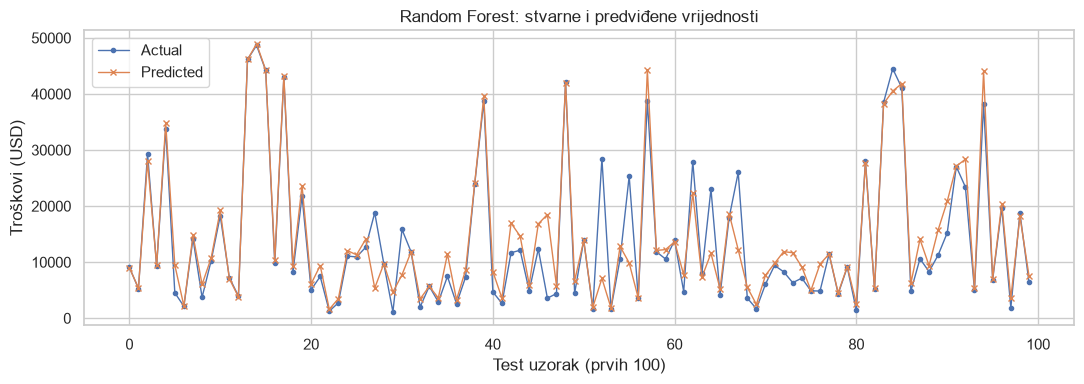

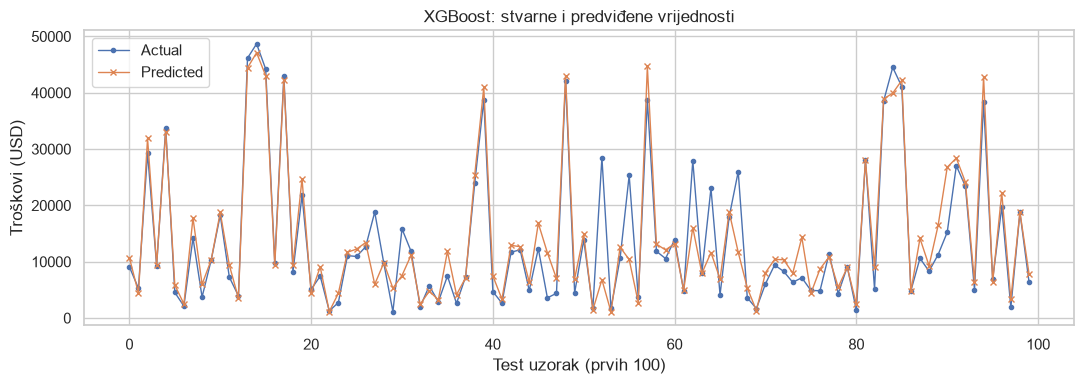

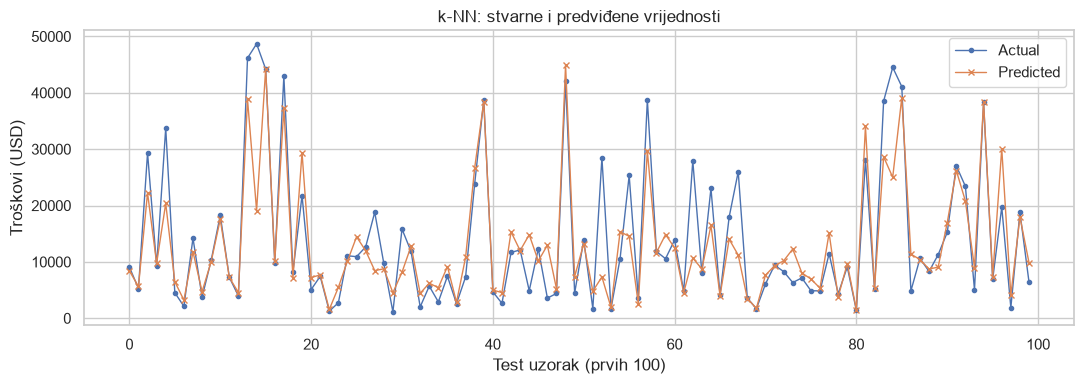

In [19]:
classical_results.to_csv(OUTPUT_DIR / "regression_classical_results.csv", index=False)

for name, predicted in classical_predictions.items():
    plot_actual_vs_predicted(
        y_test,
        predicted,
        f"{name}: stvarne i predviđene vrijednosti",
        f"actual_vs_predicted_{name.lower().replace(' ', '_').replace('-', '')}.png",
    )

# ## 5. Neuronske mreže
#
# Prva mreža ima dva skrivena sloja (64 i 32 neurona, ReLU) i trenira se s optimizatorom Adam i
# `batch_size = 32`. Druga mreža je dublja i šira (128 ReLU -> 64 tanh -> 32 ReLU), ima Dropout
# slojeve, koristi RMSprop i `batch_size = 16`. Time se mreže razlikuju po broju slojeva,
# aktivacijskim funkcijama, `batch_size` i optimizatoru.
#
# Troškovi su reda veličine 10^4, pa target prije treniranja skaliram (`StandardScaler` fitan
# samo na trening skupu). Predikcije vraćam u originalne jedinice prije izračuna MSE i MAE, da bi
# rezultati bili usporedivi s klasičnim modelima. Za rano zaustavljanje koristim
# `EarlyStopping` na validacijskom dijelu trening skupa.

In [20]:
preprocessor_nn = build_preprocessor(StandardScaler())
X_train_nn = np.asarray(preprocessor_nn.fit_transform(X_train), dtype="float32")
X_test_nn = np.asarray(preprocessor_nn.transform(X_test), dtype="float32")

target_scaler = StandardScaler()
y_train_scaled = target_scaler.fit_transform(y_train.to_numpy().reshape(-1, 1))

print(f"Trening matrica za mreže: {X_train_nn.shape}")
print(f"Testna matrica za mreže: {X_test_nn.shape}")

Trening matrica za mreže: (856, 11)
Testna matrica za mreže: (268, 11)


In [21]:
nn1_model, nn1_history, nn1_predicted, nn1_metrics = train_regression_nn(
    "Neural Network 1",
    X_train_nn,
    X_test_nn,
    hidden_layers=[64, 32],
    activations=["relu", "relu"],
    dropout_rate=0.0,
    optimizer="adam",
    batch_size=32,
)
pd.Series(nn1_metrics)

MSE            20206713.152007
MAE                 2664.95018
Model         Neural Network 1
Type                    Neural
Slojevi                      2
Neuroni                  64-32
Aktivacije           relu+relu
Dropout                    0.0
Optimizer                 adam
batch_size                  32
Epohe                       23
dtype: object

In [22]:
nn2_model, nn2_history, nn2_predicted, nn2_metrics = train_regression_nn(
    "Neural Network 2",
    X_train_nn,
    X_test_nn,
    hidden_layers=[128, 64, 32],
    activations=["relu", "tanh", "relu"],
    dropout_rate=[0.2, 0.2, 0.0],
    optimizer="rmsprop",
    batch_size=16,
)
pd.Series(nn2_metrics)

MSE            21218226.600011
MAE                2662.413347
Model         Neural Network 2
Type                    Neural
Slojevi                      3
Neuroni              128-64-32
Aktivacije      relu+tanh+relu
Dropout        [0.2, 0.2, 0.0]
Optimizer              rmsprop
batch_size                  16
Epohe                       18
dtype: object

In [23]:
neural_predictions = {"Neural Network 1": nn1_predicted, "Neural Network 2": nn2_predicted}

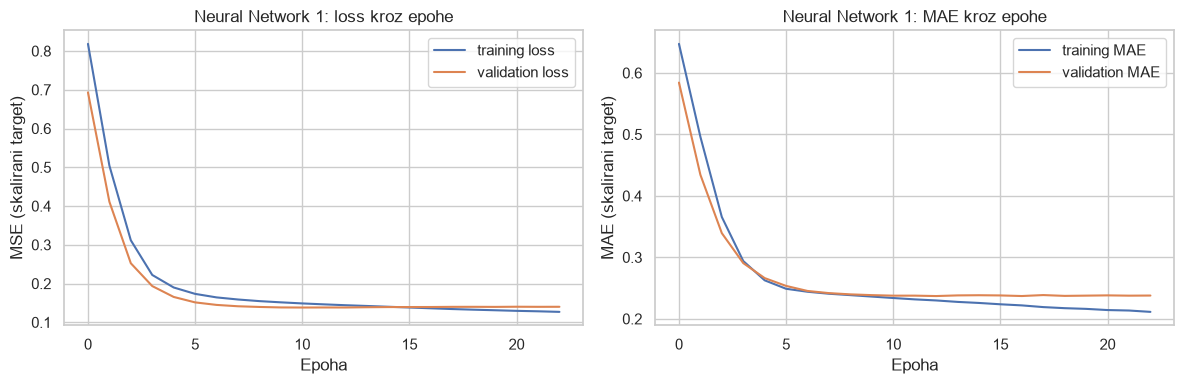

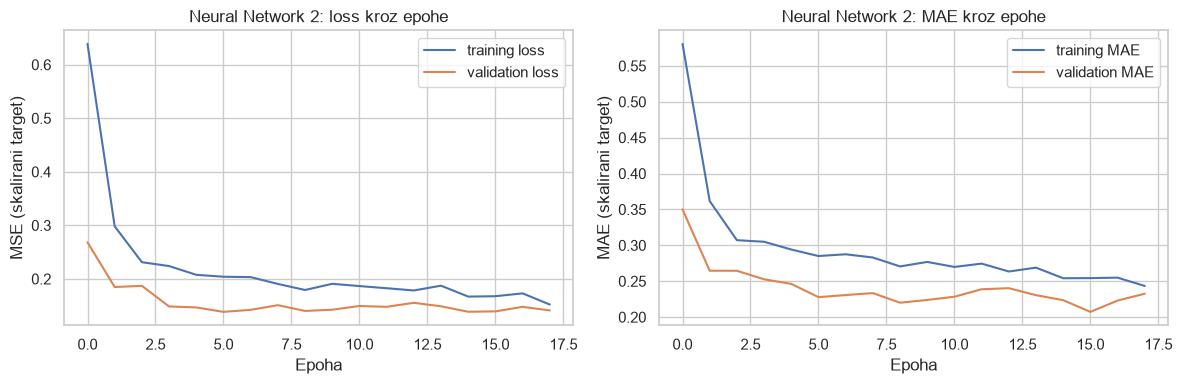

In [24]:
histories = {"Neural Network 1": nn1_history, "Neural Network 2": nn2_history}

for name, history in histories.items():
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history.history["loss"], label="training loss")
    axes[0].plot(history.history["val_loss"], label="validation loss")
    axes[0].set_title(f"{name}: loss kroz epohe")
    axes[0].set_xlabel("Epoha")
    axes[0].set_ylabel("MSE (skalirani target)")
    axes[0].legend()
    axes[1].plot(history.history["mae"], label="training MAE")
    axes[1].plot(history.history["val_mae"], label="validation MAE")
    axes[1].set_title(f"{name}: MAE kroz epohe")
    axes[1].set_xlabel("Epoha")
    axes[1].set_ylabel("MAE (skalirani target)")
    axes[1].legend()
    save_and_show(fig, f"history_{name.lower().replace(' ', '_')}.png")

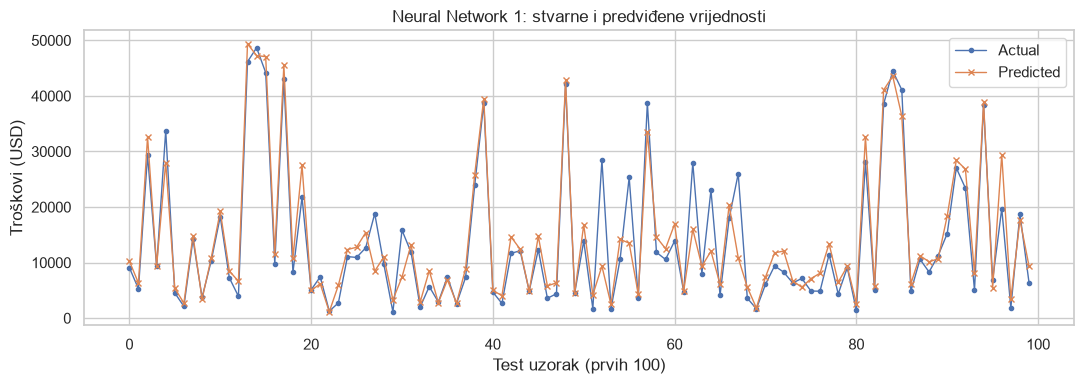

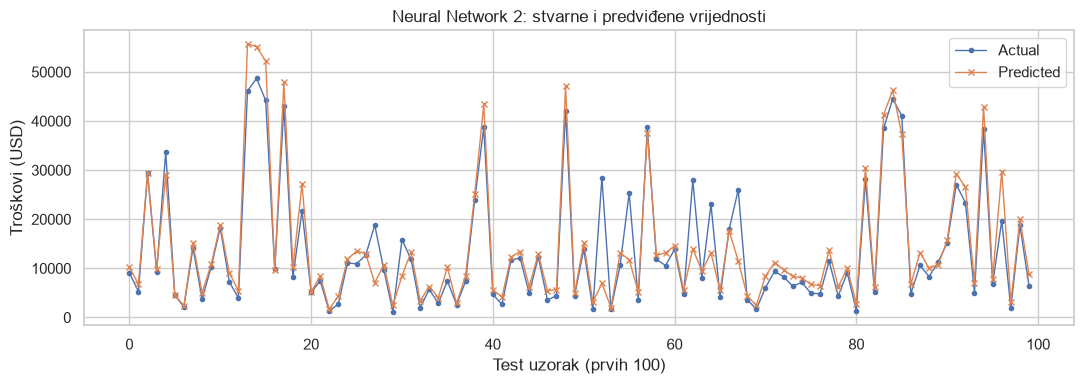

In [25]:
for name, predicted in neural_predictions.items():
    plot_actual_vs_predicted(
        y_test,
        predicted,
        f"{name}: stvarne i predviđene vrijednosti",
        f"actual_vs_predicted_{name.lower().replace(' ', '_')}.png",
    )

# ## 6. Zajednička tablica rezultata
#
# Usporedba klasičnih modela i neuronskih mreža na istom testnom skupu.

In [26]:
all_results = pd.concat(
    [
        classical_results,
        pd.DataFrame([nn1_metrics, nn2_metrics])[["Model", "Type", "MSE", "MAE"]],
    ],
    ignore_index=True,
)
all_results = all_results[["Model", "Type", "MSE", "MAE"]].round(2)
all_results.to_csv(OUTPUT_DIR / "regression_results.csv", index=False)
all_results

,Model,Type,MSE,MAE
0,Random Forest,Classical,21901936.13,2505.56
1,XGBoost,Classical,21087268.02,2567.31
2,k-NN,Classical,42931319.10,3693.21
3,Neural Network 1,Neural,20206713.15,2664.95
4,Neural Network 2,Neural,21218226.60,2662.41


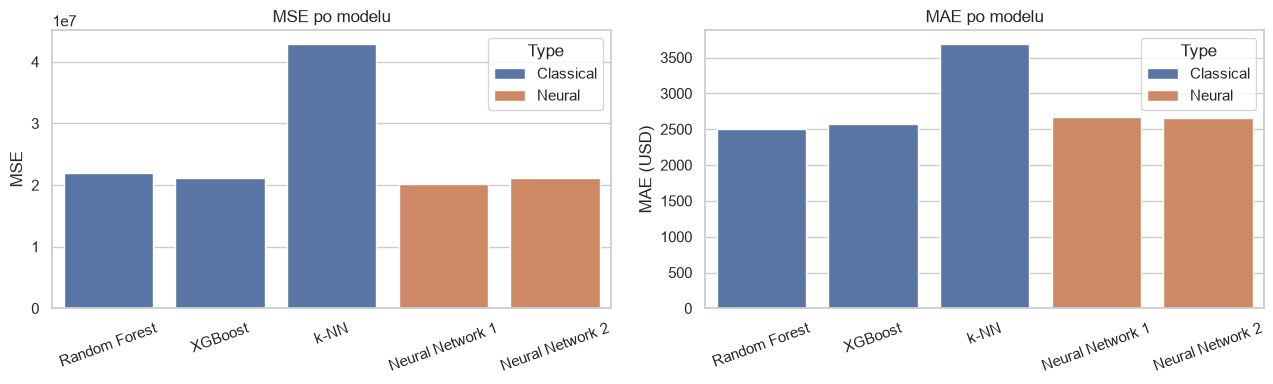

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.barplot(data=all_results, x="Model", y="MSE", hue="Type", ax=axes[0])
axes[0].set_title("MSE po modelu")
axes[0].set_xlabel("")
axes[0].set_ylabel("MSE")
axes[0].tick_params(axis="x", rotation=20)
sns.barplot(data=all_results, x="Model", y="MAE", hue="Type", ax=axes[1])
axes[1].set_title("MAE po modelu")
axes[1].set_xlabel("")
axes[1].set_ylabel("MAE (USD)")
axes[1].tick_params(axis="x", rotation=20)
save_and_show(fig, "regression_results_barplot.png")

# ## 7. Eksperimenti
#
# U eksperimentima mijenjam jedan element po jednom (skaliranje, `batch_size`, aktivacija,
# Dropout, optimizator, broj slojeva), a sve ostalo ostaje isto kao kod osnovne mreže. Svi
# eksperimenti koriste istu podjelu podataka, isti validacijski dio za rano zaustavljanje i
# isti seed.

In [28]:
base_hidden_layers = [64, 32]
base_activations = ["relu", "relu"]
base_batch_size = 32
base_optimizer = "adam"

NN_METRIC_COLUMNS = [
    "Model", "Slojevi", "Neuroni", "Aktivacije", "Dropout", "Optimizer",
    "batch_size", "Epohe", "MSE", "MAE",
]


def neural_inputs(scaler):
    """Vraća (trening, test) matrice značajki za zadanu metodu skaliranja."""
    preprocessor = build_preprocessor(scaler)
    train_input = np.asarray(preprocessor.fit_transform(X_train), dtype="float32")
    test_input = np.asarray(preprocessor.transform(X_test), dtype="float32")
    return train_input, test_input


def experiment_table(metrics_list):
    table = pd.DataFrame(metrics_list)[NN_METRIC_COLUMNS]
    return table.round(2)

# ### 7.1 Utjecaj skaliranja
#
# Uspoređujem `StandardScaler`, `MinMaxScaler` i potpuno bez skaliranja, na k-NN-u i na mreži 1.

In [29]:
scaling_rows = []
scaling_nn_metrics = []

for variant, scaler in {
    "StandardScaler": StandardScaler(),
    "MinMaxScaler": MinMaxScaler(),
    "Bez skaliranja": None,
}.items():
    knn_model = Pipeline(
        [
            ("prep", build_preprocessor(scaler)),
            ("model", KNeighborsRegressor(n_neighbors=best_k)),
        ]
    )
    knn_model.fit(X_train, y_train)
    scaling_rows.append(
        {"Model": "k-NN", "Scaler": variant, **regression_metrics(y_test, knn_model.predict(X_test))}
    )

    train_input, test_input = neural_inputs(scaler)
    _, _, _, metrics = train_regression_nn(
        f"Neural Network 1 ({variant})", train_input, test_input,
        base_hidden_layers, base_activations, batch_size=base_batch_size,
    )
    scaling_rows.append({"Model": "Neural Network 1", "Scaler": variant, "MSE": metrics["MSE"], "MAE": metrics["MAE"]})
    scaling_nn_metrics.append(metrics)

scaling_results = pd.DataFrame(scaling_rows).round(2)
scaling_results.to_csv(OUTPUT_DIR / "regression_scaling_experiment.csv", index=False)
scaling_results

,Model,Scaler,MSE,MAE
0,k-NN,StandardScaler,4.293132e+07,3693.21
1,Neural Network 1,StandardScaler,2.020671e+07,2664.95
2,k-NN,MinMaxScaler,3.463390e+07,3536.55
3,Neural Network 1,MinMaxScaler,2.209692e+07,2732.75
4,k-NN,Bez skaliranja,1.186476e+08,6923.05
5,Neural Network 1,Bez skaliranja,3.689626e+07,3541.45


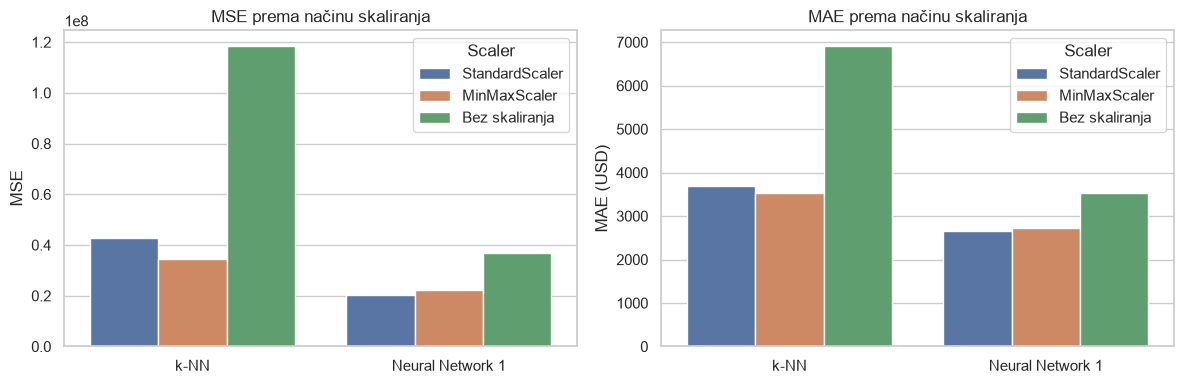

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=scaling_results, x="Model", y="MSE", hue="Scaler", ax=axes[0])
axes[0].set_title("MSE prema načinu skaliranja")
axes[0].set_xlabel("")
axes[0].set_ylabel("MSE")
sns.barplot(data=scaling_results, x="Model", y="MAE", hue="Scaler", ax=axes[1])
axes[1].set_title("MAE prema načinu skaliranja")
axes[1].set_xlabel("")
axes[1].set_ylabel("MAE (USD)")
save_and_show(fig, "experiment_scaling.png")

# ### 7.2 Utjecaj `batch_size`
#
# `batch_size = 1` je znatno sporiji po epohi, pa je za tu vrijednost broj epoha ograničen na 30;
# kod ostalih vrijednosti vrijedi standardno rano zaustavljanje.

In [31]:
batch_size_rows = []

for batch_size in [1, 16, 32, 64, 128]:
    _, _, _, metrics = train_regression_nn(
        f"batch_size = {batch_size}", X_train_nn, X_test_nn, base_hidden_layers, base_activations,
        batch_size=batch_size, max_epochs=30 if batch_size == 1 else 150,
    )
    batch_size_rows.append(metrics)

batch_size_results = experiment_table(batch_size_rows)
batch_size_results.to_csv(OUTPUT_DIR / "regression_batch_size_experiment.csv", index=False)
batch_size_results

,Model,Slojevi,Neuroni,Aktivacije,Dropout,Optimizer,batch_size,Epohe,MSE,MAE
0,batch_size = 1,2,64-32,relu+relu,0.0,adam,1,18,20887381.04,2399.94
1,batch_size = 16,2,64-32,relu+relu,0.0,adam,16,23,21426021.64,2549.65
2,batch_size = 32,2,64-32,relu+relu,0.0,adam,32,23,20206713.15,2664.95
3,batch_size = 64,2,64-32,relu+relu,0.0,adam,64,33,19740466.10,2618.82
4,batch_size = 128,2,64-32,relu+relu,0.0,adam,128,37,20836027.01,2643.43


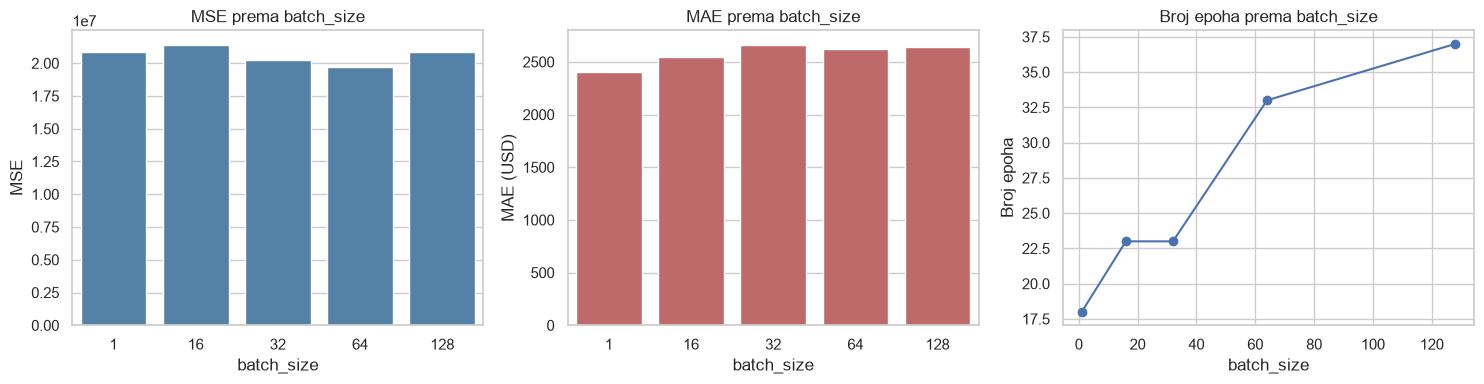

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.barplot(data=batch_size_results, x="batch_size", y="MSE", ax=axes[0], color="steelblue")
axes[0].set_title("MSE prema batch_size")
axes[0].set_xlabel("batch_size")
axes[0].set_ylabel("MSE")
sns.barplot(data=batch_size_results, x="batch_size", y="MAE", ax=axes[1], color="indianred")
axes[1].set_title("MAE prema batch_size")
axes[1].set_xlabel("batch_size")
axes[1].set_ylabel("MAE (USD)")
axes[2].plot(batch_size_results["batch_size"], batch_size_results["Epohe"], marker="o")
axes[2].set_title("Broj epoha prema batch_size")
axes[2].set_xlabel("batch_size")
axes[2].set_ylabel("Broj epoha")
save_and_show(fig, "experiment_batch_size.png")

# ### 7.3 Utjecaj aktivacijske funkcije
#
# Ista arhitektura i isti hiperparametri, mijenja se samo aktivacija u skrivenim slojevima.
# Softmax se ne testira jer je izlaz regresijski (jedan neuron bez aktivacije); softmax je
# funkcija za višeklasnu klasifikaciju.

In [33]:
activation_rows = []

for activation in ["relu", "tanh", "sigmoid"]:
    _, _, _, metrics = train_regression_nn(
        f"aktivacija = {activation}", X_train_nn, X_test_nn,
        base_hidden_layers, [activation] * len(base_hidden_layers),
        batch_size=base_batch_size,
    )
    activation_rows.append(metrics)

activation_results = experiment_table(activation_rows)
activation_results.to_csv(OUTPUT_DIR / "regression_activation_experiment.csv", index=False)
activation_results

,Model,Slojevi,Neuroni,Aktivacije,Dropout,Optimizer,batch_size,Epohe,MSE,MAE
0,aktivacija = relu,2,64-32,relu+relu,0.0,adam,32,23,20206713.15,2664.95
1,aktivacija = tanh,2,64-32,tanh+tanh,0.0,adam,32,37,21975412.74,2763.32
2,aktivacija = sigmoid,2,64-32,sigmoid+sigmoid,0.0,adam,32,150,19967723.73,2775.28


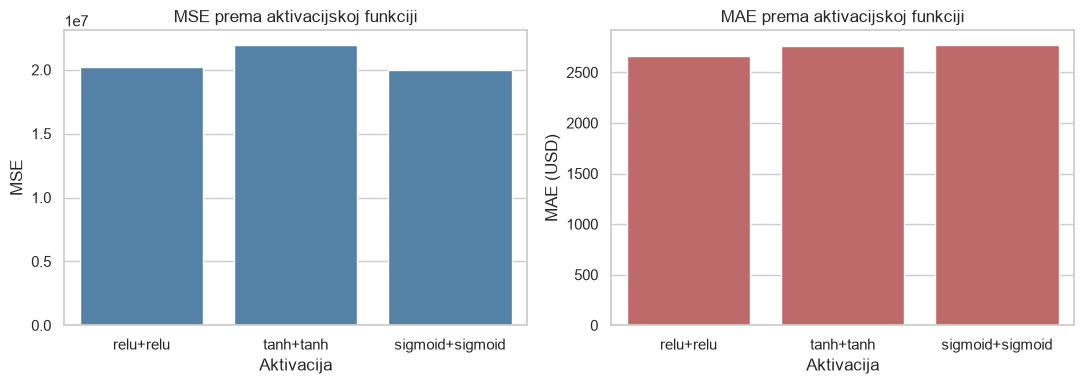

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(data=activation_results, x="Aktivacije", y="MSE", ax=axes[0], color="steelblue")
axes[0].set_title("MSE prema aktivacijskoj funkciji")
axes[0].set_xlabel("Aktivacija")
axes[0].set_ylabel("MSE")
sns.barplot(data=activation_results, x="Aktivacije", y="MAE", ax=axes[1], color="indianred")
axes[1].set_title("MAE prema aktivacijskoj funkciji")
axes[1].set_xlabel("Aktivacija")
axes[1].set_ylabel("MAE (USD)")
save_and_show(fig, "experiment_activation.png")

# ### 7.4 Utjecaj Dropouta
#
# Dropout se dodaje iza skrivenih slojeva mreže s tri sloja (128 -> 64 -> 32). Vrijednost 0
# znači da Dropouta nema.

In [35]:
dropout_rows = []
dropout_layers = [128, 64, 32]

for dropout_rate in [0.0, 0.2, 0.5]:
    _, _, _, metrics = train_regression_nn(
        f"dropout = {dropout_rate}", X_train_nn, X_test_nn,
        dropout_layers, ["relu"] * len(dropout_layers),
        dropout_rate=dropout_rate, batch_size=base_batch_size,
    )
    dropout_rows.append(metrics)

dropout_results = experiment_table(dropout_rows)
dropout_results.to_csv(OUTPUT_DIR / "regression_dropout_experiment.csv", index=False)
dropout_results

,Model,Slojevi,Neuroni,Aktivacije,Dropout,Optimizer,batch_size,Epohe,MSE,MAE
0,dropout = 0.0,3,128-64-32,relu+relu+relu,0.0,adam,32,17,21755932.74,2448.66
1,dropout = 0.2,3,128-64-32,relu+relu+relu,0.2,adam,32,44,20220575.31,2696.78
2,dropout = 0.5,3,128-64-32,relu+relu+relu,0.5,adam,32,35,24736936.05,3569.67


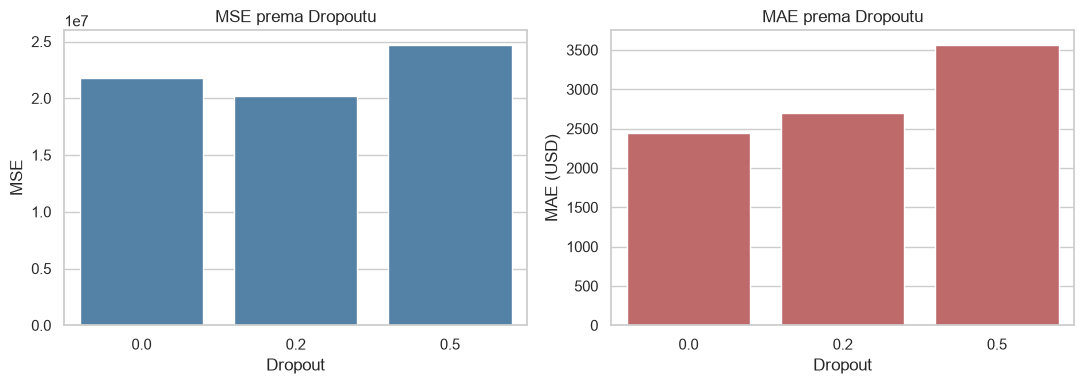

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(data=dropout_results, x="Dropout", y="MSE", ax=axes[0], color="steelblue")
axes[0].set_title("MSE prema Dropoutu")
axes[0].set_xlabel("Dropout")
axes[0].set_ylabel("MSE")
sns.barplot(data=dropout_results, x="Dropout", y="MAE", ax=axes[1], color="indianred")
axes[1].set_title("MAE prema Dropoutu")
axes[1].set_xlabel("Dropout")
axes[1].set_ylabel("MAE (USD)")
save_and_show(fig, "experiment_dropout.png")

# ### 7.5 Utjecaj optimizatora

In [37]:
optimizer_rows = []

for optimizer in ["adam", "rmsprop", "sgd"]:
    _, _, _, metrics = train_regression_nn(
        f"optimizer = {optimizer}", X_train_nn, X_test_nn,
        base_hidden_layers, base_activations, optimizer=optimizer, batch_size=base_batch_size,
    )
    optimizer_rows.append(metrics)

optimizer_results = experiment_table(optimizer_rows)
optimizer_results.to_csv(OUTPUT_DIR / "regression_optimizer_experiment.csv", index=False)
optimizer_results

,Model,Slojevi,Neuroni,Aktivacije,Dropout,Optimizer,batch_size,Epohe,MSE,MAE
0,optimizer = adam,2,64-32,relu+relu,0.0,adam,32,23,20206713.15,2664.95
1,optimizer = rmsprop,2,64-32,relu+relu,0.0,rmsprop,32,25,20346909.57,2744.57
2,optimizer = sgd,2,64-32,relu+relu,0.0,sgd,32,55,21413695.66,2615.23


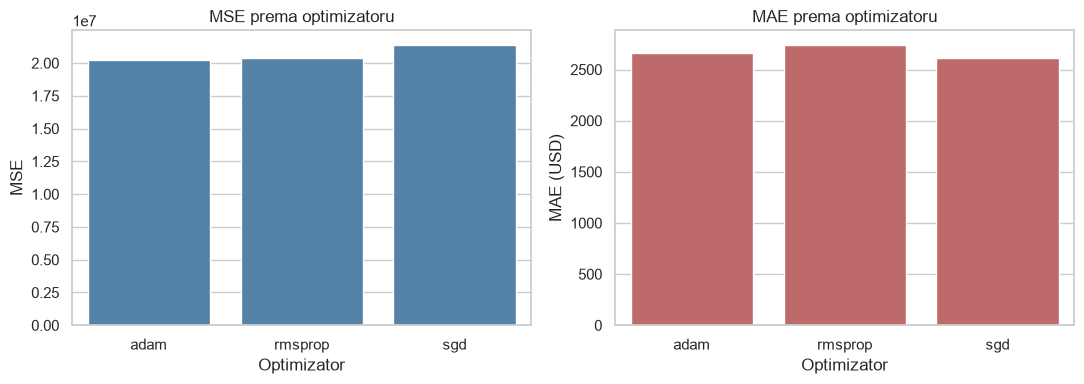

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(data=optimizer_results, x="Optimizer", y="MSE", ax=axes[0], color="steelblue")
axes[0].set_title("MSE prema optimizatoru")
axes[0].set_xlabel("Optimizator")
axes[0].set_ylabel("MSE")
sns.barplot(data=optimizer_results, x="Optimizer", y="MAE", ax=axes[1], color="indianred")
axes[1].set_title("MAE prema optimizatoru")
axes[1].set_xlabel("Optimizator")
axes[1].set_ylabel("MAE (USD)")
save_and_show(fig, "experiment_optimizer.png")

# ### 7.6 Utjecaj broja skrivenih slojeva
#
# Testiraju se mreže s jednim, dva, tri i četiri skrivena sloja.

In [39]:
layers_configurations = {
    "1 sloj": [64],
    "2 sloja": [64, 32],
    "3 sloja": [64, 32, 16],
    "4 sloja": [64, 32, 16, 8],
}
layer_rows = []

for label, hidden_layers in layers_configurations.items():
    _, _, _, metrics = train_regression_nn(
        f"{label}", X_train_nn, X_test_nn, hidden_layers, ["relu"] * len(hidden_layers),
        batch_size=base_batch_size,
    )
    layer_rows.append(metrics)

layer_results = experiment_table(layer_rows)
layer_results.to_csv(OUTPUT_DIR / "regression_layers_experiment.csv", index=False)
layer_results

,Model,Slojevi,Neuroni,Aktivacije,Dropout,Optimizer,batch_size,Epohe,MSE,MAE
0,1 sloj,1,64,relu,0.0,adam,32,54,20776230.83,2686.59
1,2 sloja,2,64-32,relu+relu,0.0,adam,32,23,20206713.15,2664.95
2,3 sloja,3,64-32-16,relu+relu+relu,0.0,adam,32,27,21793304.60,2360.48
3,4 sloja,4,64-32-16-8,relu+relu+relu+relu,0.0,adam,32,32,21731005.49,2411.49


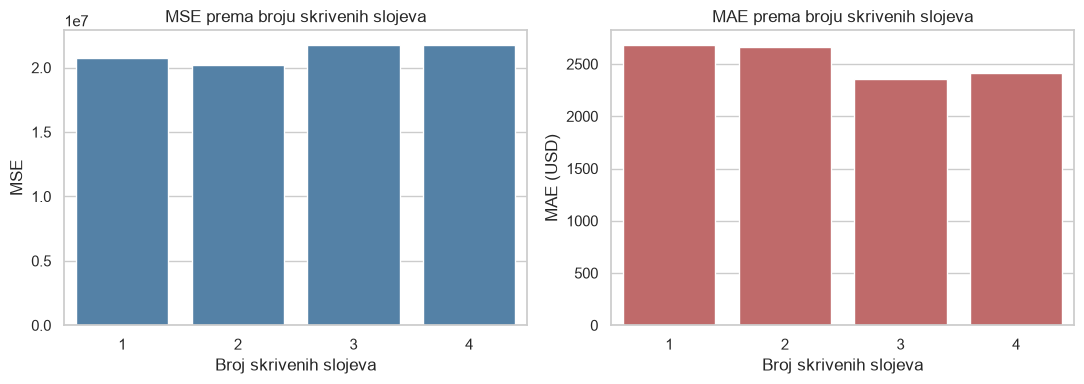

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(data=layer_results, x="Slojevi", y="MSE", ax=axes[0], color="steelblue")
axes[0].set_title("MSE prema broju skrivenih slojeva")
axes[0].set_xlabel("Broj skrivenih slojeva")
axes[0].set_ylabel("MSE")
sns.barplot(data=layer_results, x="Slojevi", y="MAE", ax=axes[1], color="indianred")
axes[1].set_title("MAE prema broju skrivenih slojeva")
axes[1].set_xlabel("Broj skrivenih slojeva")
axes[1].set_ylabel("MAE (USD)")
save_and_show(fig, "experiment_layers.png")

# ### 7.7 Sažetak svih neuronskih mreža
#
# Sve mreže iz glavnog dijela i iz eksperimenata, sortirane po MSE-u na testnom skupu.

In [41]:
all_nn_experiments = experiment_table(
    [nn1_metrics, nn2_metrics]
    + scaling_nn_metrics
    + batch_size_rows
    + activation_rows
    + dropout_rows
    + optimizer_rows
    + layer_rows
).sort_values("MSE")

all_nn_experiments.to_csv(OUTPUT_DIR / "regression_nn_experiments.csv", index=False)
all_nn_experiments

,Model,Slojevi,Neuroni,Aktivacije,Dropout,Optimizer,batch_size,Epohe,MSE,MAE
8,batch_size = 64,2,64-32,relu+relu,0.0,adam,64,33,19740466.10,2618.82
12,aktivacija = sigmoid,2,64-32,sigmoid+sigmoid,0.0,adam,32,150,19967723.73,2775.28
0,Neural Network 1,2,64-32,relu+relu,0.0,adam,32,23,20206713.15,2664.95
2,Neural Network 1 (StandardScaler),2,64-32,relu+relu,0.0,adam,32,23,20206713.15,2664.95
7,batch_size = 32,2,64-32,relu+relu,0.0,adam,32,23,20206713.15,2664.95
10,aktivacija = relu,2,64-32,relu+relu,0.0,adam,32,23,20206713.15,2664.95
20,2 sloja,2,64-32,relu+relu,0.0,adam,32,23,20206713.15,2664.95
16,optimizer = adam,2,64-32,relu+relu,0.0,adam,32,23,20206713.15,2664.95
14,dropout = 0.2,3,128-64-32,relu+relu+relu,0.2,adam,32,44,20220575.31,2696.78
17,optimizer = rmsprop,2,64-32,relu+relu,0.0,rmsprop,32,25,20346909.57,2744.57


In [42]:
best_nn = all_nn_experiments.iloc[0]
worst_nn = all_nn_experiments.iloc[-1]

print(f"Najbolja mreža: {best_nn['Model']}")
print(f"  Slojevi: {best_nn['Slojevi']} | Neuroni: {best_nn['Neuroni']} | Aktivacije: {best_nn['Aktivacije']}")
print(f"  Optimizer: {best_nn['Optimizer']} | batch_size: {best_nn['batch_size']} | Dropout: {best_nn['Dropout']}")
print(f"  MSE: {best_nn['MSE']:.2f} | MAE: {best_nn['MAE']:.2f} | Epohe: {best_nn['Epohe']}")
print()
print(f"Najslabija mreža: {worst_nn['Model']}")
print(f"  Slojevi: {worst_nn['Slojevi']} | Neuroni: {worst_nn['Neuroni']} | Aktivacije: {worst_nn['Aktivacije']}")
print(f"  Optimizer: {worst_nn['Optimizer']} | batch_size: {worst_nn['batch_size']} | Dropout: {worst_nn['Dropout']}")
print(f"  MSE: {worst_nn['MSE']:.2f} | MAE: {worst_nn['MAE']:.2f} | Epohe: {worst_nn['Epohe']}")

Najbolja mreža: batch_size = 64
  Slojevi: 2 | Neuroni: 64-32 | Aktivacije: relu+relu
  Optimizer: adam | batch_size: 64 | Dropout: 0.0
  MSE: 19740466.10 | MAE: 2618.82 | Epohe: 33

Najslabija mreža: Neural Network 1 (Bez skaliranja)
  Slojevi: 2 | Neuroni: 64-32 | Aktivacije: relu+relu
  Optimizer: adam | batch_size: 32 | Dropout: 0.0
  MSE: 36896257.97 | MAE: 3541.45 | Epohe: 53


# ### 7.8 Analiza najbolje i najslabije mreže
#
# U glavnom dijelu mreža 1 (2 sloja, ReLU, Adam, `batch_size = 32`) imala je MSE 20.206.713 i
# MAE 2665, a mreža 2 (3 sloja, ReLU/tanh, Dropout 0.2, RMSprop, `batch_size = 16`) MSE
# 21.218.227 i MAE 2662. Razlika u MSE-u je oko 5 %, a MAE im je praktički jednak, pa se ne može
# tvrditi da je dublja mreža lošija jer dio te razlike dolazi od različitog optimizatora i
# `batch_size`, ne samo od dubine.
#
# Kad se pogledaju svi eksperimenti, najniži MSE ima varijanta mreže 1 s `batch_size = 64`
# (19.740.466, MAE 2619), a najviši varijanta bez skaliranja (36.896.258, MAE 3541). Najslabija
# mreža je i očekivana: bez skaliranja numeričke varijable imaju vrlo različite raspone (`age`
# 18-64, `bmi` 16-53, `children` 0-5), pa se mreža teže prilagođava, a i zaustavila se nakon 53
# epohe.
#
# Zanimljivo je da najniži MAE imaju varijanta s `batch_size = 1` (2399.94) i mreža s tri
# skrivena sloja (2360.48), iako im MSE nije najniži. Objašnjenje je vjerojatno u tome što MSE
# jače kažnjava nekoliko velikih pogrešaka (skupina pušača s vrlo visokim troškovima), pa modeli
# koji bolje pogađaju tipične slučajeve imaju bolji MAE, dok im nekoliko velikih promašaja kvari
# MSE. Rangiranje modela zato ovisi o metrici koju gledam.
#
# Potrebno je naglasiti da je testni skup velik 268 uzoraka, pa dio razlika između konfiguracija
# može doći od slučajnosti u inicijalizaciji i redoslijedu uzoraka. Zato razlike opisujem kao
# moguće uzroke, a ne kao dokazane.

In [43]:
print("Spremljeni CSV rezultati:")
for path in sorted(OUTPUT_DIR.glob("*.csv")):
    print(" -", path.name)
print(f"Broj spremljenih grafova: {len(list(OUTPUT_DIR.glob('*.png')))}")

Spremljeni CSV rezultati:
 - regression_activation_experiment.csv
 - regression_batch_size_experiment.csv
 - regression_classical_results.csv
 - regression_dropout_experiment.csv
 - regression_layers_experiment.csv
 - regression_nn_experiments.csv
 - regression_optimizer_experiment.csv
 - regression_results.csv
 - regression_scaling_experiment.csv
Broj spremljenih grafova: 19


# ## 8. Zaključak
#
# Među klasičnim modelima Random Forest je postigao MSE 21.901.936 i MAE 2506, XGBoost MSE
# 21.087.268 i MAE 2567, a k-NN MSE 42.931.319 i MAE 3693. Random Forest ima najbolji MAE, a
# XGBoost najbolji MSE, pri čemu je razlika između ta dva modela vrlo mala. k-NN je uvjerljivo
# najslabiji, što je i očekivano jer se oslanja na geometrijske udaljenosti u prostoru s puno
# one-hot značajki koje slabo opisuju cilj.
#
# Kod neuronskih mreža prva mreža (MSE 20.206.713, MAE 2665) imala je nešto niži MSE od druge
# (MSE 21.218.227, MAE 2662), dok su po MAE bile praktički izjednačene. Najniži MSE kroz sve
# eksperimente imala je varijanta prve mreže s batch_size = 64 (19.740.466, MAE 2619), a najslabija
# je očekivano bila varijanta bez skaliranja (36.896.258, MAE 3541).
#
# Usporedba klasičnih modela i neuronskih mreža pokazuje da su rezultati istog reda veličine:
# MSE se kreće između 19,7 i 21,9 milijuna, a MAE između 2360 i 2665 (zanemarujući najlošije
# varijante). Na temelju ovog testnog skupa ne može se tvrditi da su neuronske mreže bolje od
# klasičnih modela ni obrnuto: najbolji MAE ima Random Forest, a najniži MSE jedna konfiguracija
# mreže. Za dataset ove veličine (1338 redaka) klasični modeli stabala su potpuno konkurentni i
# brži za treniranje.
#
# Skaliranje se pokazalo najvažnijim pojedinačnim korakom u pripremi podataka. Mreža bez skaliranja
# imala je 82 % veći MSE (36.896.258 u odnosu na 20.206.713), a k-NN bez skaliranja čak 118.647.617
# (dok je sa StandardScalerom imao 42.931.319, a s MinMaxScalerom 34.634.901). Zanimljivo je da je
# kod k-NN-a MinMaxScaler dao bolji rezultat, dok je za mrežu bolji bio StandardScaler.
#
# Utjecaj ostalih hiperparametara bio je umjeren. Veličina batcha od 64 dala je najniži MSE, a batch
# veličine 1 najniži MAE (uz ograničenje na 30 epoha). Kod regularizacije, Dropout od 0 i 0.2 dali su
# slične rezultate, dok je 0.5 bio osjetno lošiji (MSE 24.736.936, MAE 3570) jer je uz rano zaustavljanje
# to očito bilo previše regularizacije. Kod aktivacija tanh je bio najlošiji (MSE 21.975.413), dok je
# sigmoid imao prividno najniži MSE (19.967.724), ali uz najlošiji MAE (2775) i maksimalnih 150 epoha,
# pa to ne smatram stvarnom prednošću. Optimizatori Adam (20.206.713) i RMSprop (20.346.910) nadmašili
# su SGD (21.413.696). Povećanje broja slojeva nije donijelo napredak jer su dva skrivena sloja imala
# najniži MSE, dok su jednostavnija i dublja varijanta bile nešto slabije.
#
# Sve razlike među uspješnijim konfiguracijama relativno su male, a dio njih proizlazi i iz slučajnosti
# uslijed malog testnog skupa i inicijalizacije težina. Glavnina preostale pogreške kod svih modela
# dolazi od skupine nepušača s neuobičajeno visokim troškovima, gdje ulazne značajke jednostavno ne
# nude dovoljno objašnjenja.